# 25 · Cameras: RGB, depth, segmentation, multiple views and camera randomization

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt
from vlacourse import TableTop, show_images

def seg_to_masks(seg, model):
    """seg[...,0] = object id, seg[...,1] = object type. Returns {geom_name: mask} for geoms."""
    masks = {}
    geom = seg[..., 1] == mujoco.mjtObj.mjOBJ_GEOM
    for gid in np.unique(seg[..., 0][geom]):
        body = model.body(model.geom_bodyid[gid]).name
        masks.setdefault(body, np.zeros(seg.shape[:2], bool))
        masks[body] |= geom & (seg[..., 0] == gid)
    return masks

def colorize(seg):
    rng = np.random.default_rng(0)
    palette = rng.integers(0, 255, (seg[..., 0].max() + 2, 3)).astype(np.uint8)
    return palette[seg[..., 0] + 1]

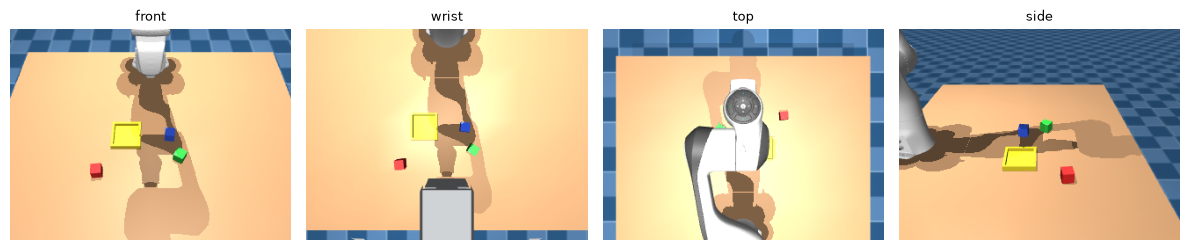

In [2]:
env = TableTop(seed=2, cameras=("front", "wrist", "top", "side"), image_size=(240, 320))
obs = env.observe()
show_images(list(obs["images"].values()), list(obs["images"]), cols=4)

rgb (240, 320, 3) uint8 | depth (240, 320) float32 [0.40, 2.67] m | seg (240, 320, 2) int32


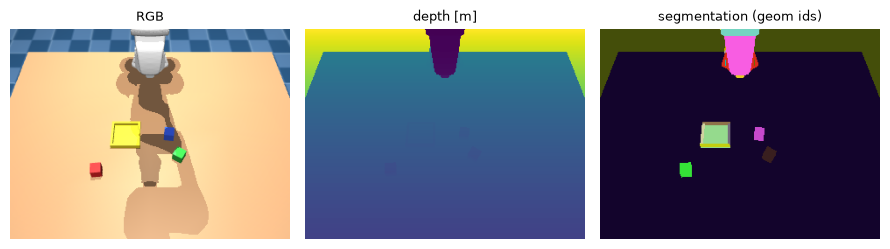

In [3]:
rgb = env.render("front")
depth = env.render("front", depth=True)
seg = env.render("front", segmentation=True)
print("rgb", rgb.shape, rgb.dtype, "| depth", depth.shape, depth.dtype, f"[{depth.min():.2f}, {depth.max():.2f}] m", "| seg", seg.shape, seg.dtype)
show_images([rgb, depth, colorize(seg)], ["RGB", "depth [m]", "segmentation (geom ids)"])

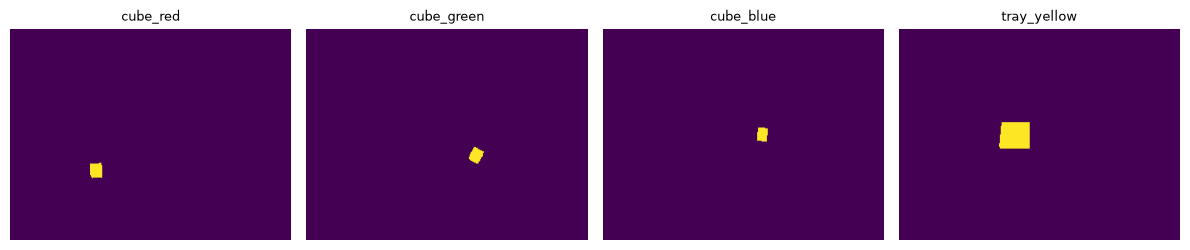

cube_red     pixels=  222  bbox=(91,152)-(104,169)
cube_green   pixels=  203  bbox=(185,134)-(201,152)
cube_blue    pixels=  172  bbox=(176,112)-(187,127)
tray_yellow  pixels= 1006  bbox=(114,106)-(148,135)


In [4]:
masks = seg_to_masks(seg, env.model)
objects = {k: v for k, v in masks.items() if k.startswith(("cube", "tray"))}
show_images([v.astype(float) for v in objects.values()], list(objects), cols=len(objects))
for k, v in objects.items():
    ys, xs = np.nonzero(v)
    print(f"{k:12s} pixels={v.sum():5d}  bbox=({xs.min()},{ys.min()})-({xs.max()},{ys.max()})")

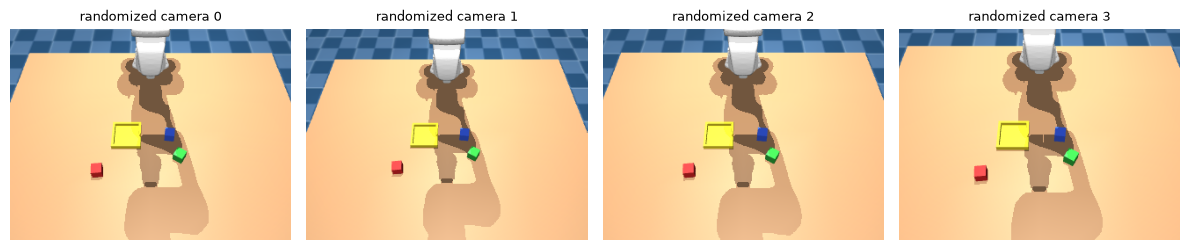

In [5]:
cid = env.model.camera("front").id
base_pos, base_quat, base_fov = env.model.cam_pos[cid].copy(), env.model.cam_quat[cid].copy(), env.model.cam_fovy[cid]
rng = np.random.default_rng(0)
views = []
for _ in range(4):
    env.model.cam_pos[cid] = base_pos + rng.normal(0, 0.03, 3)
    env.model.cam_fovy[cid] = base_fov + rng.normal(0, 4)
    views.append(env.render("front"))
env.model.cam_pos[cid], env.model.cam_fovy[cid] = base_pos, base_fov
show_images(views, [f"randomized camera {i}" for i in range(4)], cols=4)

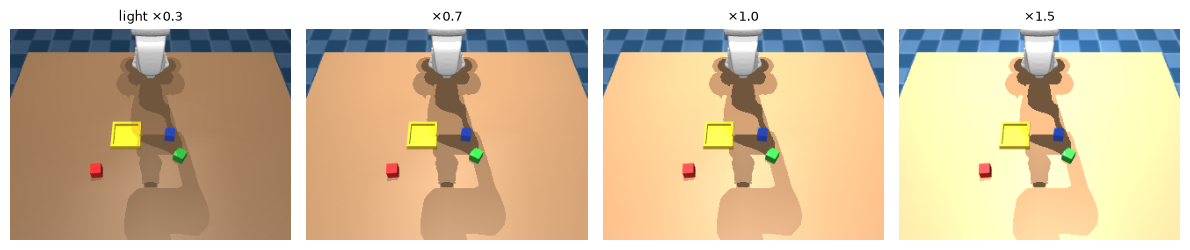

In [6]:
light = env.model.light_diffuse.copy()
imgs = []
for scale in [0.3, 0.7, 1.0, 1.5]:
    env.model.light_diffuse[:] = np.clip(light * scale, 0, 1)
    imgs.append(env.render("front"))
env.model.light_diffuse[:] = light
show_images(imgs, ["light ×0.3", "×0.7", "×1.0", "×1.5"], cols=4)